# Figure 3: Monthly Mean Temperature Comparison

This figure compares the monthly mean temperatures in June, July, and August between two periods: the early period (1991–2000) and the recent period (2016–2025), using observations from the Hong Kong Observatory Headquarters.

The x-axis represents the three summer months, while the y-axis represents the monthly mean temperature (°C). Each data point represents the average monthly mean temperature across the 10 complete summers within the corresponding period.

The data are obtained from `data/metrics/period_monthly_summary.csv`, using the `average_monthly_mean_temp_c` metric.

The early period is represented in blue (`#246C8A`), while the recent period is represented in orange (`#C05A37`), following the colour scheme used in Figure 4.

This figure provides a descriptive comparison between two periods. It does not represent a year-by-year trend or establish a causal relationship.

In [9]:
from pathlib import Path
import csv
import math
import re

import matplotlib as mpl
from IPython.display import Image
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure


# ============================================================
# 1. Locate the project directory
# ============================================================

current_directory = Path.cwd()

project_root = next(
    (
        candidate
        for candidate in (
            current_directory,
            *current_directory.parents
        )
        if (
            candidate / "data/metrics/period_monthly_summary.csv"
        ).is_file()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Cannot locate the project directory. "
        "Please open this Notebook inside the project folder."
    )

input_path = (
    project_root
    / "data"
    / "metrics"
    / "period_monthly_summary.csv"
)


# ============================================================
# 2. Load the existing metrics CSV
# ============================================================

# Use Python's built-in csv module.
# No Polars or pandas is required.

with input_path.open(
    "r",
    encoding="utf-8-sig",
    newline="",
) as csv_file:

    reader = csv.DictReader(csv_file)

    column_names = reader.fieldnames

    rows = [
        row
        for row in reader
        if any((value or "").strip() for value in row.values())
    ]

if not column_names or not rows:
    raise ValueError("The input CSV is empty or invalid.")


# The temperature column is specified in the project report.
temperature_column = "average_monthly_mean_temp_c"

if temperature_column not in column_names:
    raise ValueError(
        f"Missing required column: {temperature_column}\n"
        f"Available columns: {column_names}"
    )


# ============================================================
# 3. Identify columns using the actual CSV schema
# ============================================================

period_column = "period"
month_column = "month"
temperature_column = "average_monthly_mean_temp_c"

required_columns = {
    period_column,
    month_column,
    temperature_column,
}

missing_columns = required_columns - set(column_names)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("Period column:", period_column)
print("Month column:", month_column)
print("Temperature column:", temperature_column)

# ============================================================
# 4. Identify the period column
# ============================================================

expected_periods = {
    "1991–2000",
    "2016–2025"
}


def identify_period(value):
    """Identify whether a value belongs to the early or recent period."""

    if value is None:
        return None

    label = str(value).strip()
    normalized = label.casefold()

    years = {
        int(year)
        for year in re.findall(r"\d{4}", label)
    }

    if (
        {1991, 2000}.issubset(years)
        or "early" in normalized
        or "早期" in normalized
    ):
        return "1991–2000"

    if (
        {2016, 2025}.issubset(years)
        or "recent" in normalized
        or "近期" in normalized
    ):
        return "2016–2025"

    return None


# Identify the period column by examining its actual values.
period_candidates = []

for column in other_columns:

    normalized_values = [
        identify_period(row.get(column))
        for row in rows
    ]

    if (
        all(value is not None for value in normalized_values)
        and set(normalized_values) == expected_periods
    ):
        period_candidates.append(column)


if len(period_candidates) != 1:

    print("Available CSV columns:", column_names)
    print("Identified month column:", month_column)
    print("Period candidates:", period_candidates)

    print("\nFirst six rows of remaining columns:")

    for column in other_columns:
        print(
            f"{column}: "
            f"{[row.get(column) for row in rows[:6]]}"
        )

    raise ValueError(
        "Could not identify the period column uniquely. "
        "Please check the CSV values above."
    )


period_column = period_candidates[0]

print("Identified period column:", period_column)


# ============================================================
# 5. Organise the data
# ============================================================

temperature_by_period = {}

for row_number, row in enumerate(rows, start=2):

    raw_period = (row.get(period_column) or "").strip()

    month = parse_month(row.get(month_column))

    raw_temperature = (
        row.get(temperature_column) or ""
    ).strip()

    if not raw_period or month is None or not raw_temperature:
        raise ValueError(
            f"Missing data at CSV row {row_number}."
        )

    period = identify_period(raw_period)

    try:
        temperature = float(raw_temperature)
    except ValueError as error:
        raise ValueError(
            f"Invalid temperature at row {row_number}."
        ) from error

    if not math.isfinite(temperature):
        raise ValueError(
            f"Invalid numerical value at row {row_number}."
        )

    period_values = temperature_by_period.setdefault(
        period, {}
    )

    if month in period_values:
        raise ValueError(
            f"Duplicate observation: {period}, month {month}."
        )

    period_values[month] = temperature


# ============================================================
# 6. Validate the data
# ============================================================

expected_periods = {
    "1991–2000",
    "2016–2025"
}

if set(temperature_by_period) != expected_periods:
    raise ValueError(
        f"Unexpected periods: {set(temperature_by_period)}"
    )

for period, monthly_values in temperature_by_period.items():

    if set(monthly_values) != {6, 7, 8}:
        raise ValueError(
            f"Incomplete monthly data for {period}."
        )


# Display the prepared data.

print("Monthly Mean Temperature (°C)")
print("--------------------------------------")
print("Period       June     July    August")

for period in ("1991–2000", "2016–2025"):

    values = temperature_by_period[period]

    print(
        f"{period}  "
        f"{values[6]:7.3f}  "
        f"{values[7]:7.3f}  "
        f"{values[8]:7.3f}"
    )

Period column: period
Month column: month
Temperature column: average_monthly_mean_temp_c
Identified period column: period
Monthly Mean Temperature (°C)
--------------------------------------
Period       June     July    August
1991–2000   28.207   28.681   28.502
2016–2025   28.973   29.680   29.025


In [10]:
# ============================================================
# 1. Figure style
# ============================================================

style = {
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "text.color": "#243746",
    "axes.labelcolor": "#243746",
    "xtick.color": "#51616D",
    "ytick.color": "#51616D",
    "svg.fonttype": "path",
}


# ============================================================
# 2. Create the figure
# ============================================================

months = [6, 7, 8]

month_labels = [
    "June",
    "July",
    "August"
]

period_styles = [
    ("1991–2000", "#246C8A"),
    ("2016–2025", "#C05A37"),
]


with mpl.rc_context(style):

    figure = Figure(
        figsize=(8.6, 6.4),
        facecolor="white",
    )

    canvas = FigureCanvasAgg(figure)

    axes = figure.add_axes(
        (0.115, 0.235, 0.84, 0.59)
    )


    # ========================================================
    # 3. Plot the two periods
    # ========================================================

    for period, color in period_styles:

        temperatures = [
            temperature_by_period[period][month]
            for month in months
        ]

        axes.plot(
            months,
            temperatures,
            color=color,
            linewidth=2.2,
            marker="o",
            markersize=7,
            markeredgecolor="white",
            markeredgewidth=0.8,
            label=f"{period} (n = 10 years)",
            zorder=3,
        )

        # Add numerical labels beside each point.

        label_offset = (
            -16 if period == "1991–2000" else 9
        )

        for month, temperature in zip(
            months,
            temperatures,
            strict=True,
        ):

            axes.annotate(
                f"{temperature:.2f}",
                xy=(month, temperature),
                xytext=(0, label_offset),
                textcoords="offset points",
                ha="center",
                fontsize=9,
                color=color,
            )


    # ========================================================
    # 4. X-axis configuration
    # ========================================================

    axes.set_xticks(
        months,
        month_labels,
    )

    axes.set_xlim(5.75, 8.25)

    axes.set_xlabel(
        "Month",
        labelpad=12,
    )


    # ========================================================
    # 5. Y-axis configuration
    # ========================================================

    all_temperatures = [
        temperature_by_period[period][month]
        for period in ("1991–2000", "2016–2025")
        for month in months
    ]

    temperature_min = min(all_temperatures)
    temperature_max = max(all_temperatures)

    padding = max(
        0.25,
        (temperature_max - temperature_min) * 0.25,
    )

    axes.set_ylim(
        temperature_min - padding,
        temperature_max + padding,
    )

    axes.set_ylabel(
        "Monthly mean temperature (°C)",
        labelpad=12,
    )


    # ========================================================
    # 6. Grid and axes styling
    # ========================================================

    axes.grid(
        axis="y",
        color="#E5EAED",
        linewidth=0.7,
        zorder=0,
    )

    axes.set_axisbelow(True)

    axes.spines["top"].set_visible(False)
    axes.spines["right"].set_visible(False)

    for spine in ("left", "bottom"):
        axes.spines[spine].set_color("#B8C3CA")

    axes.tick_params(
        length=3,
        color="#B8C3CA",
    )

    axes.legend(
        loc="upper left",
        frameon=False,
        fontsize=9,
    )


    # ========================================================
    # 7. Figure title and subtitle
    # ========================================================

    figure.text(
        0.115,
        0.93,
        "Figure 3. Monthly mean temperature by period",
        fontsize=16,
        weight="bold",
    )

    figure.text(
        0.115,
        0.88,
        (
            "Hong Kong Observatory · June–August · "
            "1991–2000 vs 2016–2025 · "
            "n = 10 complete summers per period"
        ),
        fontsize=10,
        color="#51616D",
    )


    # ========================================================
    # 8. Notes and source
    # ========================================================

    figure.text(
        0.115,
        0.10,
        (
            "Each point is the period-average monthly mean "
            "temperature across 10 complete summers."
        ),
        fontsize=8.5,
        color="#51616D",
    )

    figure.text(
        0.115,
        0.06,
        (
            "Source: Hong Kong Observatory daily observations; "
            "project period monthly metrics."
        ),
        fontsize=8.5,
        color="#51616D",
    )

## Save and Export

The figure is exported in two formats:

- PNG: A high-resolution raster image at 300 dpi, suitable for the final project report.
- SVG: A vector image that can be resized without losing quality.

Both files are saved in the project's `figures/` directory.

The SVG font is converted into paths to maintain consistent typography across different computers.

PNG saved: d:\ama2233\ama2233-hk-summer-weather\figures\03_monthly_temperature_comparison.png
SVG saved: d:\ama2233\ama2233-hk-summer-weather\figures\03_monthly_temperature_comparison.svg


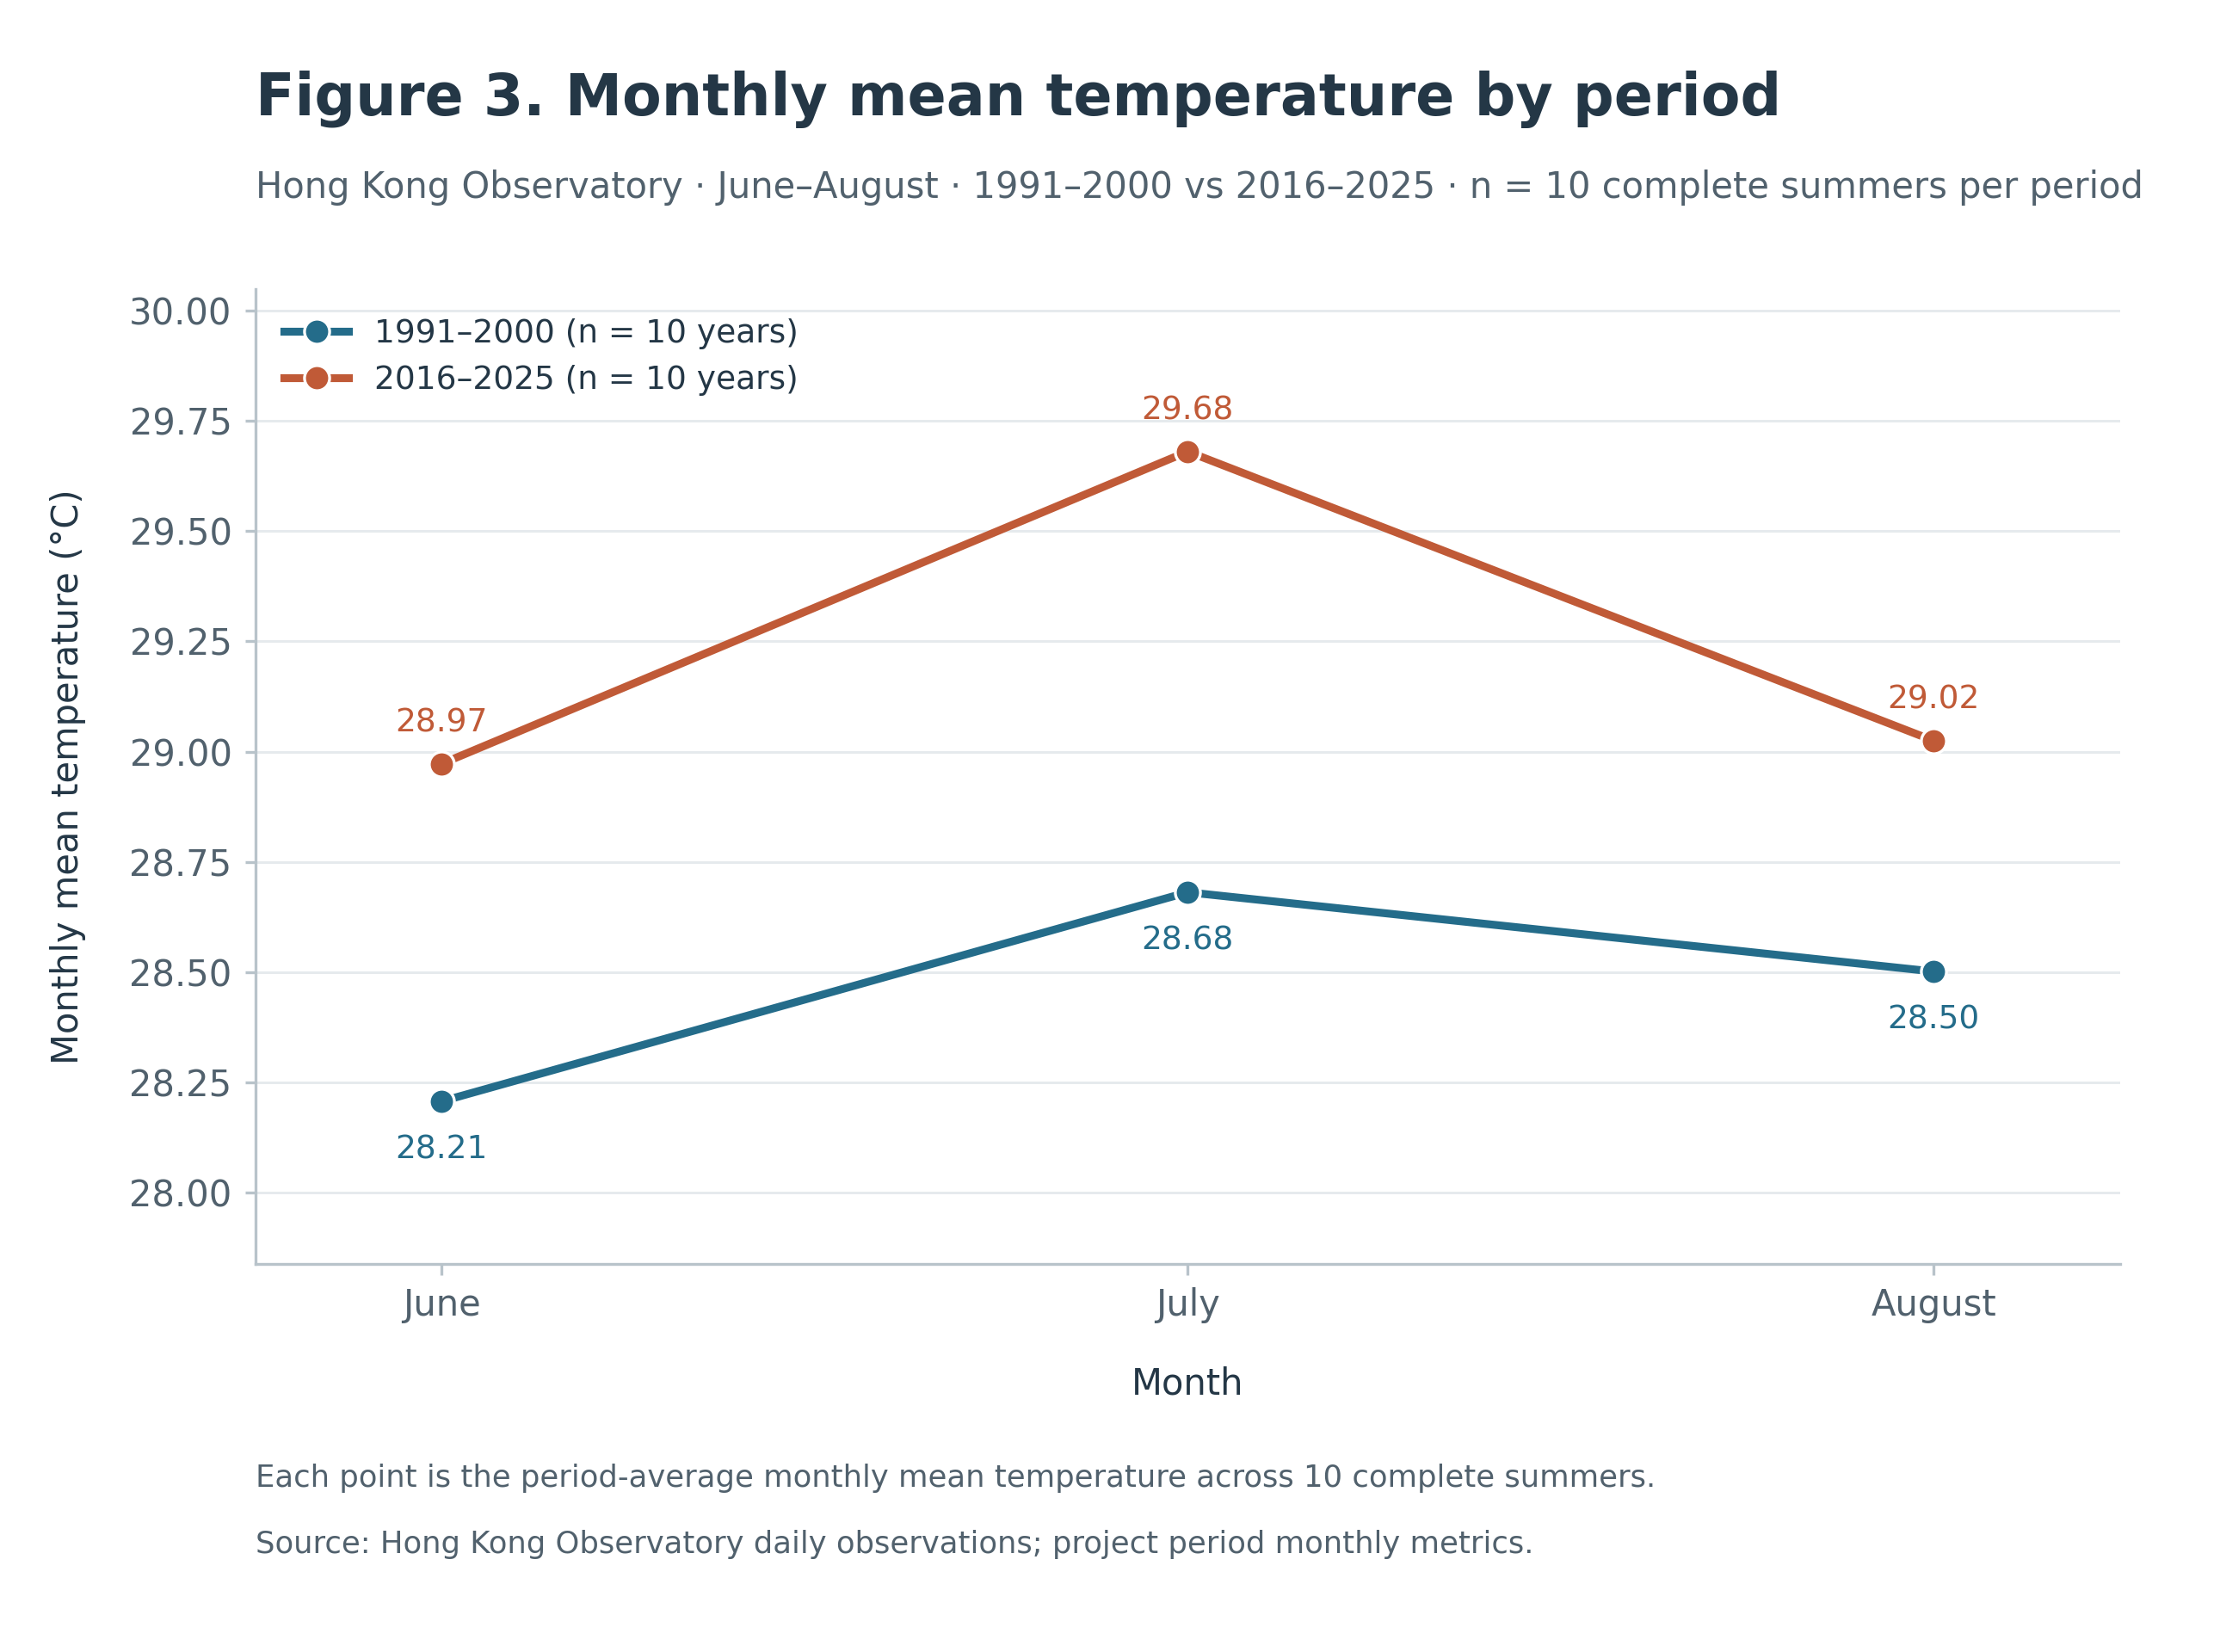

In [11]:
# ============================================================
# 1. Define output paths
# ============================================================

output_dir = project_root / "figures"

output_dir.mkdir(
    parents=True,
    exist_ok=True,
)

png_path = (
    output_dir
    / "03_monthly_temperature_comparison.png"
)

svg_path = (
    output_dir
    / "03_monthly_temperature_comparison.svg"
)


# ============================================================
# 2. Save PNG and SVG
# ============================================================

with mpl.rc_context(style):

    figure.savefig(
        png_path,
        dpi=300,
        facecolor="white",
    )

    figure.savefig(
        svg_path,
        facecolor="white",
    )


# ============================================================
# 3. Display the generated figure
# ============================================================

print(f"PNG saved: {png_path}")
print(f"SVG saved: {svg_path}")

Image(
    filename=str(png_path),
    width=860,
)
